--> Arquivo carregado: data/prova_cn.csv
--> Total de estudantes: 109
--> Estrutura das colunas: ['estudante', 'datetime', 'pontuacao', 'serie_turma', 'materia', '0', '1', '2', '3', '4'] ...

 Dimensão da matriz codificada em One-Hot: (109, 136)


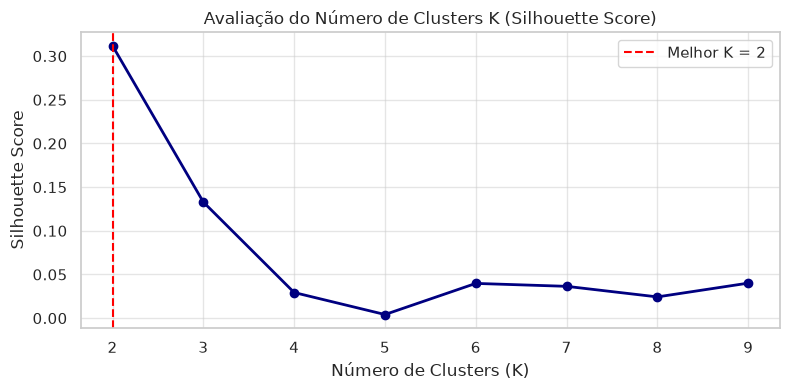

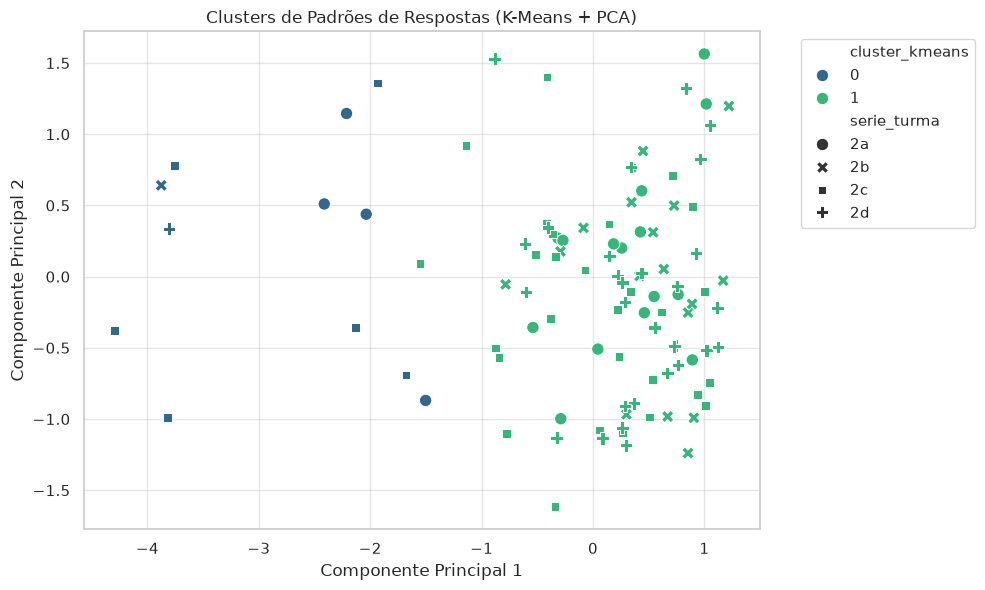

 PARES COM ALTA SUSPEITA IDENTIFICADOS: 118


,Estudante_A,Estudante_B,Turma_A,Turma_B,Mesma_Turma,Questões_Divergentes,Diferença_Tempo_Min,Horário_A,Horário_B,Pontuação_A,Pontuação_B,Mesmo_Cluster,Score_Suspeita
0,1586,425,2a,2a,True,0,0.00,2025-07-17 13:53:09,2025-07-17 13:53:35,2792,2792,True,1000.0
31,1415,1083,2b,2b,True,0,0.00,2025-07-17 18:31:16,2025-07-17 18:31:16,2584,2584,True,1000.0
51,450,736,2b,2b,True,0,0.00,2025-07-17 09:03:04,2025-07-17 09:03:04,2688,2688,True,1000.0
52,450,1055,2b,2b,True,0,0.00,2025-07-17 09:03:04,2025-07-17 09:03:08,2688,2688,True,1000.0
49,450,1447,2b,2b,True,0,0.00,2025-07-17 09:03:04,2025-07-17 09:03:03,2688,2688,True,1000.0
71,1447,1055,2b,2b,True,0,0.00,2025-07-17 09:03:03,2025-07-17 09:03:08,2688,2688,True,1000.0
83,736,1055,2b,2b,True,0,0.00,2025-07-17 09:03:04,2025-07-17 09:03:08,2688,2688,True,1000.0
70,1447,736,2b,2b,True,0,0.00,2025-07-17 09:03:03,2025-07-17 09:03:04,2688,2688,True,1000.0
69,1447,1329,2b,2b,True,0,0.07,2025-07-17 09:03:03,2025-07-17 09:58:42,2688,2688,True,600.0
78,1329,736,2b,2b,True,0,0.07,2025-07-17 09:58:42,2025-07-17 09:03:04,2688,2688,True,600.0


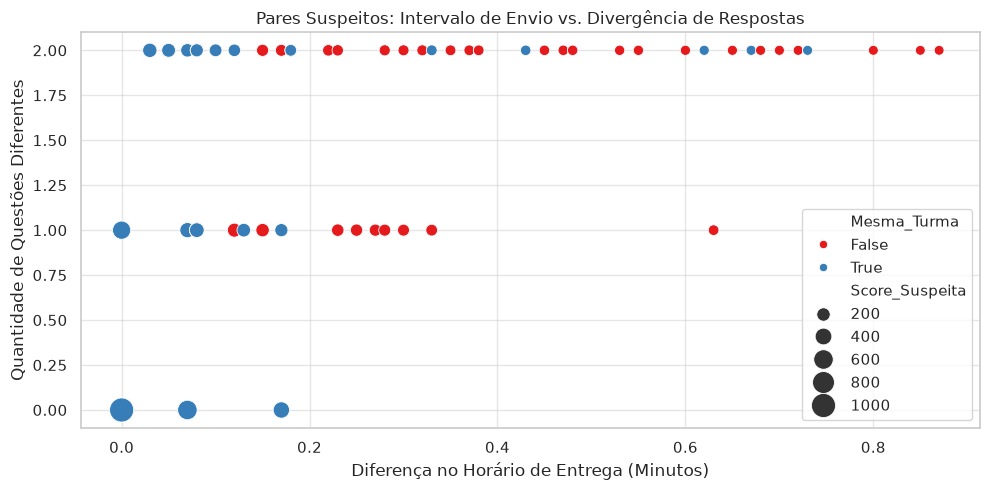

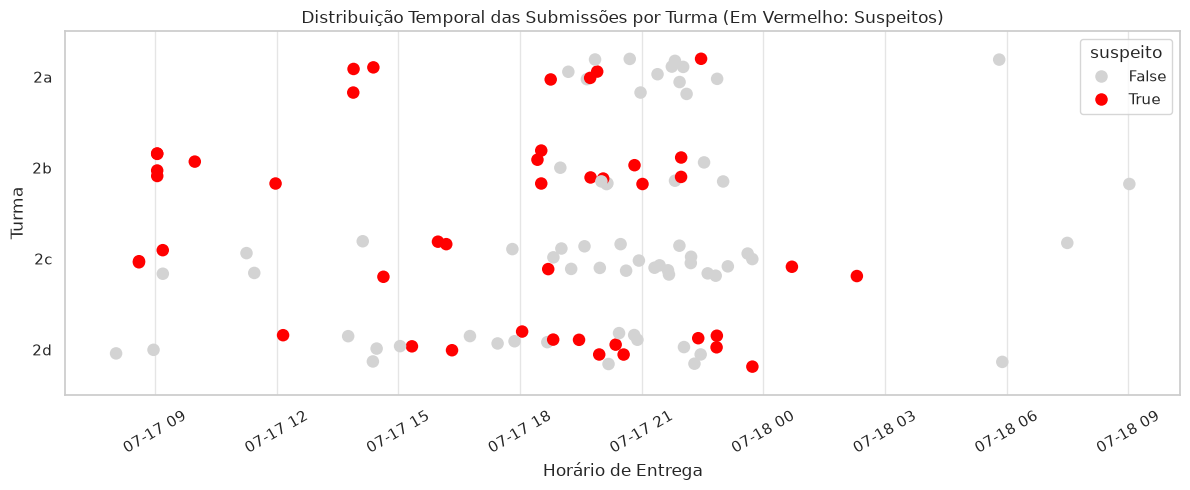


 RELATÓRIO FINAL: GRUPOS / REDES DE COLA DETECTADAS

Grupo 1 - Total de 37 Estudantes Envolvidos: [105, 128, 132, 141, 235, 420, 425, 450, 463, 702, 736, 943, 955, 963, 1050, 1055, 1083, 1221, 1242, 1262, 1293, 1302, 1329, 1330, 1377, 1414, 1415, 1447, 1465, 1545, 1547, 1575, 1584, 1586, 1619, 1624, 1675]
  • Turma(s): ['2a', '2b', '2c', '2d']
  • Horários de Envio: ['2025-07-17 13:53:09', '2025-07-17 13:53:35', '2025-07-17 14:22:54', '2025-07-17 18:45:15', '2025-07-17 19:54:02', '2025-07-17 18:31:16', '2025-07-17 21:01:04', '2025-07-17 09:03:04', '2025-07-17 18:31:16', '2025-07-17 11:58:12', '2025-07-17 18:25:40', '2025-07-17 19:44:14', '2025-07-17 20:02:55', '2025-07-17 09:03:03', '2025-07-17 20:49:15', '2025-07-17 09:58:42', '2025-07-17 09:03:04', '2025-07-17 09:03:08', '2025-07-17 16:10:45', '2025-07-17 14:37:46', '2025-07-18 00:42:07', '2025-07-17 15:58:29', '2025-07-17 09:11:18', '2025-07-17 18:41:36', '2025-07-18 02:18:13', '2025-07-17 20:33:09', '2025-07-17 20:21:22', '2025-07

In [6]:
# ==============================================================================
# ETAPA 1: IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÃO DO AMBIENTE
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform
import networkx as nx

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# ==============================================================================
# ETAPA 2: CARREGAMENTO E PRÉ-PROCESSAMENTO DOS DADOS
# ==============================================================================
# Tentativa de carregar o arquivo informado
file_name = 'prova_cn_2.csv'
try:
    df = pd.read_csv(file_name)
except FileNotFoundError:
    file_name = 'data/prova_cn.csv'
    df = pd.read_csv(file_name)

print(f"--> Arquivo carregado: {file_name}")
print(f"--> Total de estudantes: {df.shape[0]}")
print(f"--> Estrutura das colunas: {list(df.columns[:10])} ...\n")

# Identificar as colunas que contêm as respostas das questões
question_cols = [col for col in df.columns if col.isdigit()]
if not question_cols:
    question_cols = [str(i) for i in range(29) if str(i) in df.columns]

# Matriz de respostas tratadas (garantindo valores inteiros)
answers_df = df[question_cols].fillna(-1).astype(int)

# Conversão dos horários de entrega para datetime e Unix Timestamps (segundos)
df['datetime_dt'] = pd.to_datetime(df['datetime'])
df['timestamp_sec'] = df['datetime_dt'].astype('int64') // 10**9

# ==============================================================================
# ETAPA 3: CODIFICAÇÃO ONE-HOT ENCODING (OHE)
# ==============================================================================
ohe = OneHotEncoder(sparse_output=False)
X_ohe = ohe.fit_transform(answers_df)

print(f" Dimensão da matriz codificada em One-Hot: {X_ohe.shape}")

# ==============================================================================
# ETAPA 4: AGRUPAMENTO DOS ESTUDANTES COM K-MEANS
# ==============================================================================
# Avaliação da pontuação de silhueta para determinar o número ideal de clusters (K)
silhouette_scores = []
k_range = range(2, min(10, len(df)))

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_ohe)
    score = silhouette_score(X_ohe, labels)
    silhouette_scores.append(score)

best_k = k_range[np.argmax(silhouette_scores)]

# Gráfico de Avaliação de K (Método da Silhueta)
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', color='navy', linewidth=2)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Melhor K = {best_k}')
plt.title('Avaliação do Número de Clusters K (Silhouette Score)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.tight_layout()
plt.show()

# Treinamento do K-Means final
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_final.fit_predict(X_ohe)

# Redução de Dimensionalidade (PCA) para visualização 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_ohe)
df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='pca1', y='pca2', hue='cluster_kmeans', style='serie_turma' if 'serie_turma' in df.columns else None, palette='viridis', s=80)
plt.title('Clusters de Padrões de Respostas (K-Means + PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ==============================================================================
# ETAPA 5: DISTÂNCIA DE HAMMING E DIFERENÇA TEMPORAL ENTRE PARES
# ==============================================================================
num_questoes = len(question_cols)

# Distância de Hamming normalizada [0, 1] convertida para quantidade exata de questões divergentes
hamming_norm = squareform(pdist(answers_df.values, metric='hamming'))
questoes_divergentes_matrix = np.round(hamming_norm * num_questoes).astype(int)

# Matriz de diferença temporal de entrega (em minutos)
times = df['timestamp_sec'].values
diferenca_tempo_min_matrix = np.abs(times[:, None] - times[None, :]) / 60.0

# ==============================================================================
# ETAPA 6: IDENTIFICAÇÃO DE PARES SUSPEITOS E CÁLCULO DO SCORE DE SUSPEITA
# ==============================================================================
n_alunos = len(df)
pares_suspeitos = []

# Critérios para flag de suspeita: até 2 questões divergentes e entrega dentro de 10 minutos
MAX_DIVERGENCIAS = 2
MAX_TEMPO_MINUTOS = 10.0

for i in range(n_alunos):
    for j in range(i + 1, n_alunos):
        diff_q = questoes_divergentes_matrix[i, j]
        diff_t = diferenca_tempo_min_matrix[i, j]
        mesma_turma = (df.loc[i, 'serie_turma'] == df.loc[j, 'serie_turma']) if 'serie_turma' in df.columns else True
        mesmo_cluster = (df.loc[i, 'cluster_kmeans'] == df.loc[j, 'cluster_kmeans'])

        if diff_q <= MAX_DIVERGENCIAS and diff_t <= MAX_TEMPO_MINUTOS:
            # Fórmula do Score de Suspeita Composto
            score_suspeita = round((1 / (diff_q + 1)) * (1 / (diff_t + 0.1)) * 100, 2)

            pares_suspeitos.append({
                'Estudante_A': df.loc[i, 'estudante'],
                'Estudante_B': df.loc[j, 'estudante'],
                'Turma_A': df.loc[i, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Turma_B': df.loc[j, 'serie_turma'] if 'serie_turma' in df.columns else 'N/A',
                'Mesma_Turma': mesma_turma,
                'Questões_Divergentes': diff_q,
                'Diferença_Tempo_Min': round(diff_t, 2),
                'Horário_A': df.loc[i, 'datetime'],
                'Horário_B': df.loc[j, 'datetime'],
                'Pontuação_A': df.loc[i, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Pontuação_B': df.loc[j, 'pontuacao'] if 'pontuacao' in df.columns else 'N/A',
                'Mesmo_Cluster': mesmo_cluster,
                'Score_Suspeita': score_suspeita
            })

df_suspeitos = pd.DataFrame(pares_suspeitos)

if not df_suspeitos.empty:
    df_suspeitos = df_suspeitos.sort_values(by='Score_Suspeita', ascending=False)
    print("=========================================================")
    print(f" PARES COM ALTA SUSPEITA IDENTIFICADOS: {len(df_suspeitos)}")
    print("=========================================================")
    display(df_suspeitos.head(15))
else:
    print("Nenhum par atendeu aos critérios de suspeita delimitados.")

# ==============================================================================
# ETAPA 7: VISUALIZAÇÕES ANALÍTICAS AVANÇADAS
# ==============================================================================
if not df_suspeitos.empty:
    # 1. Gráfico de Dispersão: Tempo vs. Divergência
    plt.figure(figsize=(10, 5))
    sns.scatterplot(
        data=df_suspeitos,
        x='Diferença_Tempo_Min',
        y='Questões_Divergentes',
        hue='Mesma_Turma',
        size='Score_Suspeita',
        sizes=(50, 300),
        palette='Set1'
    )
    plt.title('Pares Suspeitos: Intervalo de Envio vs. Divergência de Respostas')
    plt.xlabel('Diferença no Horário de Entrega (Minutos)')
    plt.ylabel('Quantidade de Questões Diferentes')
    plt.tight_layout()
    plt.show()

    # 2. Timeline de Envios com Destaque para Alunos Suspeitos
    estudantes_suspeitos_ids = set(df_suspeitos['Estudante_A']).union(set(df_suspeitos['Estudante_B']))
    df['suspeito'] = df['estudante'].isin(estudantes_suspeitos_ids)

    plt.figure(figsize=(12, 5))
    sns.stripplot(
        data=df,
        x='datetime_dt',
        y='serie_turma' if 'serie_turma' in df.columns else None,
        hue='suspeito',
        palette={False: 'lightgray', True: 'red'},
        size=9,
        jitter=0.2
    )
    plt.title('Distribuição Temporal das Submissões por Turma (Em Vermelho: Suspeitos)')
    plt.xlabel('Horário de Entrega')
    plt.ylabel('Turma' if 'serie_turma' in df.columns else '')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ==============================================================================
# ETAPA 8: DETECÇÃO DE REDES/GRUPOS DE COLA VIA GRAFOS (NETWORKX)
# ==============================================================================
if not df_suspeitos.empty:
    G = nx.Graph()
    for _, row in df_suspeitos.iterrows():
        G.add_edge(row['Estudante_A'], row['Estudante_B'], weight=row['Score_Suspeita'])

    grupos_conectados = list(nx.connected_components(G))

    print("\n=========================================================")
    print(" RELATÓRIO FINAL: GRUPOS / REDES DE COLA DETECTADAS")
    print("=========================================================\n")

    for idx, grupo in enumerate(grupos_conectados, start=1):
        sub_df = df[df['estudante'].isin(grupo)]
        turmas = sub_df['serie_turma'].unique() if 'serie_turma' in sub_df.columns else ['N/A']
        horarios = sub_df['datetime'].tolist()
        pontuacoes = sub_df['pontuacao'].tolist() if 'pontuacao' in sub_df.columns else ['N/A']

        print(f"Grupo {idx} - Total de {len(grupo)} Estudantes Envolvidos: {sorted(list(grupo))}")
        print(f"  • Turma(s): {list(turmas)}")
        print(f"  • Horários de Envio: {horarios}")
        print(f"  • Pontuações do Grupo: {pontuacoes}")
        print("---------------------------------------------------------")